# Sea surface height in ACCESS-OM3 and observations

## Setting up

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/5

https://access-nri.zulipchat.com/#narrow/channel/470332-ocean-seaice/topic/Evaluation/near/512462625

 - SSH - SEALEVEL_GLO_PHY_L4_MY_008_047 is in kj13 /g/data/kj13/datasets/cosima/CMEMS and have started a CMORiser in ESMValTool working for monthly
 - AVISO Altimetry Antarctic -kj13 : /g/data/kj13/datasets/cosima/AVISO-Altimetry

Both the above are also in:
 - /g/data/av17/access-nri-temporary/OM3/CMEMS
 - /g/data/av17/access-nri-temporary/OM3/AVISO-Altimetry

Hacked from:
 - https://cosima-recipes.readthedocs.io/en/latest/02-Appetisers/Compare_SSH_model_obs.html (nb: `ua8` is no longer accepting new members)
 - https://github.com/ACCESS-Community-Hub/access-om3-paper-1/blob/main/notebooks/SST.ipynb

Related chat:
 - https://access-nri.zulipchat.com/#narrow/channel/470332-ocean-seaice/topic/Evaluation/near/544659613
 - https://github.com/COSIMA/cosima-recipes/issues/549

NB: with 25km monthly output runs okay on an ARE "large" job.

**If using the daily sattelite obs one needs to use `normalsr` queue with 104 cores/496 Gb**

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json"
papermill = True
cwd = "/g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/"
nbname = "SSH.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs

In [4]:
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from textwrap import wrap
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default
import glob

In [5]:
client = Client(threads_per_worker=1)
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:34905,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35831,Total threads: 1
Dashboard: http://127.0.0.1:38727/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:42579,


In [6]:
#here we set the years that we are interested in

start_time = '1993-01-01'
end_time = '2023-12-31'

start_year=int(start_time.split('-')[0])
end_year=int(end_time.split('-')[0])


## SSH from 0.25$^{\circ}$ ACCESS-OM3 model output

In [7]:
from exptdata_access import get_exptname_from_path
exptname = get_exptname_from_path(esm_file)

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

In [8]:
exptname

'MC_100km_jra_iaf+wombatlite-test1-e1de2a94'

In [9]:
from model_agnostic import get_lon_lat_from_catalog
geolon, geolat = get_lon_lat_from_catalog(datastore)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504a6c5e690>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504a68a0710>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504a68a17f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504a68a1fa0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504a71f2150>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504a71f2090>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1504a5150230>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [10]:
variable = "zos"
model_all = datastore.search(variable=variable).to_dask(
    xarray_open_kwargs = dict(
        chunks={"time": -1},
        decode_timedelta=True
    ),
    xarray_combine_by_coords_kwargs=dict(
        compat="override",
        data_vars="minimal",
        coords="minimal"
    )
)[variable].cf.assign_coords({ "longitude": geolon, "latitude": geolat })

In [11]:
#model_all

In [12]:
# omit latitudes with grid bug https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
# -- only affects the 25km-iaf-test-for-AK-expt-7df5ef4c experiment specifically
if exptname == "25km-iaf-test-for-AK-expt-7df5ef4c":
    model_all = model_all.isel(yh=slice(10, None))
    geolon = geolon.isel(yh=slice(10, None))
    geolat = geolat.isel(yh=slice(10, None))

In [13]:
# for IAF
model_all = model_all.convert_calendar("proleptic_gregorian", use_cftime=True)

In [14]:
model_all.time.values[0] # initial date in data

cftime.DatetimeProlepticGregorian(1958, 1, 16, 12, 0, 0, 0, has_year_zero=True)

In [15]:
model_all.time.values[-1] # final date in data

cftime.DatetimeProlepticGregorian(2023, 12, 16, 12, 0, 0, 0, has_year_zero=True)

In [16]:
# set time range

# timerange = slice(cftime.DatetimeNoLeap(1942, 1, 1, 0, 0, 0, 0),
#                   cftime.DatetimeNoLeap(1952, 1, 1, 0, 0, 0, 0))
# timerange = slice(None, None)
# datestop = model_all.time.values[-1] # final date in data

datestart= cftime.DatetimeProlepticGregorian(start_year, 1,  16, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
datestop = cftime.DatetimeProlepticGregorian(end_year, 12, 16, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
timerange = slice(datestart, datestop)

In [17]:
datestart

cftime.DatetimeProlepticGregorian(1993, 1, 16, 12, 0, 0, 0, has_year_zero=True)

In [18]:
datestop

cftime.DatetimeProlepticGregorian(2023, 12, 16, 12, 0, 0, 0, has_year_zero=True)

In [19]:
model_all = model_all.sel(time=timerange)

In [20]:
%%time
model_mean = model_all.mean('time').load()

CPU times: user 350 ms, sys: 165 ms, total: 515 ms
Wall time: 551 ms


In [21]:
%%time
# this should really use the square field (although it makes the om2 comparison apples-to-oranges)
model_std = model_all.std('time').load()

CPU times: user 614 ms, sys: 206 ms, total: 820 ms
Wall time: 940 ms


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


## SSH from 0.25$^{\circ}$ ACCESS-OM2 model output

In [22]:
# SSH variable in ACCESS-OM2 models
variable = 'sea_level'

catalog = intake.cat.access_nri
var_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable=variable, frequency='1mon')
ds = var_search.to_dask()
ssh025 = ds[variable].sel(time=slice(start_time, end_time))

You can see we have a very large number of chunks, so lets rechunk.

In [23]:
ssh025 = ssh025.chunk({'time': 'auto'})

In [24]:
%%time
#this cell will take a bit (few minutes)
# 0.25 deg:
ssh025_mean = ssh025.mean(dim='time').load()
ssh025_std  = ssh025.std(dim='time', skipna=False).load()

CPU times: user 2.86 s, sys: 1.16 s, total: 4.03 s
Wall time: 9.44 s


In [25]:
var_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable="area_t")
ds = var_search.search(path=var_search.df["path"][0]).to_dask()
geolon_t_025 = ds.geolon_t
geolat_t_025 = ds.geolat_t

ssh025_mean = ssh025_mean.assign_coords({"geolon_t": geolon_t_025, "geolat_t": geolat_t_025})
ssh025_std = ssh025_std.assign_coords({"geolon_t": geolon_t_025, "geolat_t": geolat_t_025})

## Read in observations

In [26]:
import numpy as np
filenames=[]

#for debugging if you want a tiny dataset
# for year in np.arange(start_year,1994+1):
#     filenames.append(sorted(glob.glob("/g/data/av17/access-nri-temporary/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/"+str(year)+"/11/*1101_*15*.nc")))

#for daily data
for year in np.arange(start_year,end_year+1):
    #print(year)
    filenames.append(sorted(glob.glob("/g/data/av17/access-nri/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/"+str(year)+"/*/*.nc")))

#for monthly data
# for year in np.arange(start_year,end_year+1):
#     #print(year)
#     filenames.append(sorted(glob.glob("/g/data/av17/access-nri-temporary/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1M-m_202411/"+str(year)+"/*.nc")))

#make list of lists into just a list
filenames = [item for sublist in filenames for item in sublist]

In [27]:
%%time
#this was taking ages on daily data, so Dougie suggested adding: data_vars='minimal', coords='minimal', compat='override' -- should avoid any issues with messy metadata -- see docs: https://docs.xarray.dev/en/stable/generated/xarray.open_mfdataset.html
cmems = xr.open_mfdataset(filenames, parallel=True,concat_dim="time", combine="nested", data_vars='minimal', coords='minimal', compat='override',chunks="auto")

#even betterer (I think these extra ones actually slowed it down a bit?)
#concat_dim="time", combine="nested", data_vars='minimal', coords='minimal', compat='override'

#faster with 28 cores compared to 14 (~1.5 minutes)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x147af870ea50>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e405a95700>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14af35faeae0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x148280def080>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14aed338ebd0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f290338fe0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x148863ceb830>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f2882a7c20>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x148861b6d850>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


CPU times: user 6min 41s, sys: 3min 3s, total: 9min 45s
Wall time: 11min 59s


In [28]:
#filenames

In [29]:
# for daily files
# The absolute dynamic topography is the sea surface height above geoid; the adt is obtained as follows: adt=sla+mdt where mdt is the mean dynamic topography; see the product user manual for details
obs_ssh = cmems.adt 
obs_ssh = obs_ssh.rename('adt_cmems')

# for daily files
# obs_ssh = cmems.sla 
# obs_ssh = obs_ssh.rename('adt_cmems')


In [30]:
%%time
#on daily data this cell didn't run properly with 28 cores/252 gb. Needed `normalsr` queue with 104 cores/496 Gb
obs_ssh_mean = obs_ssh.mean(dim='time').load()
obs_ssh_std  = obs_ssh.std(dim='time', skipna=False).load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 21.50 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 21.50 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 5min 44s, sys: 1min 48s, total: 7min 33s
Wall time: 18min 8s


In [31]:
#from Anton -- could use this kind of command to reduce the obs down to the model frequency but I think it makes more sense to use ssh^2 fields from model.
#obs_ssh_mean= obs_ssh.groupbyt('time.month').mean('time').std(dim='time', skipna=False)
#obs_ssh_std = obs_ssh.groupbyt('time.month').mean('time').std(dim='time', skipna=False)

#AS: sorry - this should be a resample not a groupby !
#AS: groupby would give a climatology (a monthly mean of all years). resample would give a mean for every month (e.g like change from daily to monthly data)

## Plot ACCESS-OM2, ACCESS-OM3 and obs


Saved /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SSH_01.png
Adding entry to per-notebook markdown: /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SSH.md
This title already exists in the notebook markdown – appending an additional figure.


Lines appended to /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/SSH.md successfully.
CPU times: user 1min 7s, sys: 17 s, total: 1min 24s
Wall time: 1min 7s


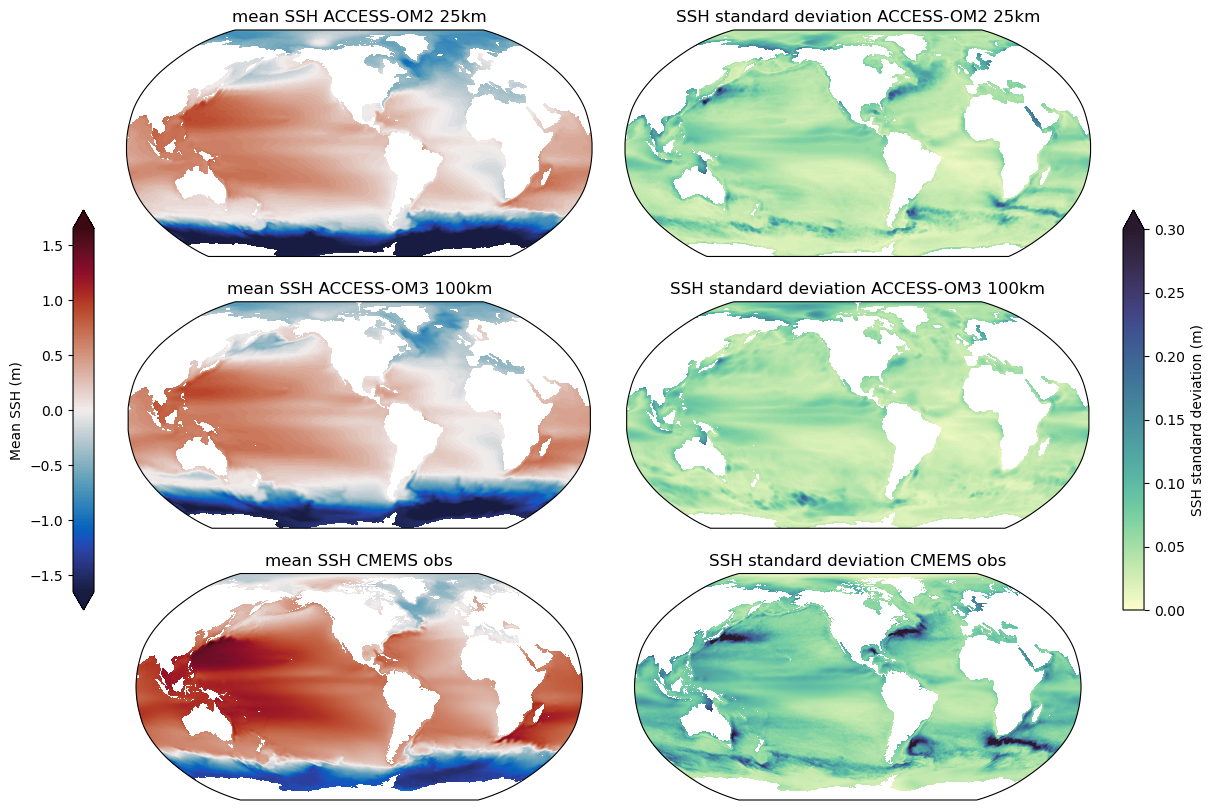

In [32]:
%%time

# nominal resolution from the model grid, so titles are right for any OM3 resolution
nx = model_mean.sizes["xh"]
om3_res = {360: "100km", 1440: "25km", 4320: "8km"}.get(nx)

projection = ccrs.Robinson(central_longitude=-100)

fig, axes = plt.subplots(nrows = 3, ncols = 2, figsize = (14, 10),
                         subplot_kw={'projection': projection})
plt.subplots_adjust(wspace=-0.15)

max_std = 0.3
max_mean = 1.65

# mean SSH plots
ax = axes[0, 0]
p1 = ssh025_mean.plot.contourf(
    ax = ax,
    x = "geolon_t",
    y = "geolat_t",
    levels = 100,
    vmin = -max_mean,
    vmax = +max_mean,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
ax.set_title('mean SSH ACCESS-OM2 25km')

ax = axes[1, 0]
p1 = model_mean.plot.contourf(
    ax = ax,
    x = "xh",
    y = "yh",
    levels = 100,
    vmin = -max_mean,
    vmax = +max_mean,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
ax.set_title(f'mean SSH ACCESS-OM3 {om3_res}')

ax = axes[2, 0]
p1 = obs_ssh_mean.plot(ax=ax, transform=ccrs.PlateCarree(),
                       cmap=cm.cm.balance, vmin=-max_mean, vmax=max_mean, add_colorbar=False)
ax.set_title('mean SSH CMEMS obs')

# std SSH plots
ax = axes[0, 1]
p2 = ssh025_std.plot.contourf(
    ax = ax,
    x = "geolon_t",
    y = "geolat_t",
    levels = 100,
    vmin = 0,
    vmax = max_std,
    add_colorbar=False,
    cmap = cm.cm.deep,
    transform = ccrs.PlateCarree())
ax.set_title('SSH standard deviation ACCESS-OM2 25km')

ax = axes[1, 1]
p2 = model_std.plot.contourf(
    ax = ax,
    x = "xh",
    y = "yh",
    levels = 100,
    vmin = 0,
    vmax = max_std,
    add_colorbar=False,
    cmap = cm.cm.deep,
    transform = ccrs.PlateCarree())
ax.set_title(f'SSH standard deviation ACCESS-OM3 {om3_res}')

ax = axes[2, 1]
p2 = obs_ssh_std.plot(ax=ax, transform=ccrs.PlateCarree(),cmap=cm.cm.deep, vmin=0, vmax=max_std, add_colorbar=False)
ax.set_title('SSH standard deviation CMEMS obs')

# Colorbars
ax_cb1 = plt.axes([0.13, 0.3, 0.015, 0.4])
cb = plt.colorbar(p1, cax=ax_cb1, extend='both', label='Mean SSH (m)')
ax_cb1.yaxis.set_ticks_position('left')
ax_cb1.yaxis.set_label_position('left')

ax_cb2 = plt.axes([0.88, 0.3, 0.015, 0.4])
cb = plt.colorbar(p2, cax=ax_cb2, extend='max', label='SSH standard deviation (m)');
mkmd.savefig(fig, "Sea Surface Height", "Sea surface height mean and standard deviation comparison for ACCESS-OM3 and ACCESS-OM2. [GitHub issue: Global dynamic sea level](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/4) [GitHub issue: Sea level anomaly std dev](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/5)")

In [33]:
plt.show()